# Nucleolar protein intensity quantification
In this notebook, we show how we quantify the distribution of nucleolar TFs- Ubtf around the nucleolus in speckle KD (SON KD, SRRM2 KD and Double KD) and Ubtf overexpression conditions.
In brief, we segment the nucleus and nucleolus using the DAPI channel. We use speckle marker proteins (if available) to improve nucleoli segmentation (speckle protein dense regions are not nucleoli but have low DAPI intensity, which can lead to false positive nucleolus). Then, we make a 2um thick ring around and the nucleolus and measure the mean Fbl/Npm1 intensity in this single ring.

In [1]:
import fishtools as ft
import warnings
import numpy as np
import os
import pandas as pd
from aicsimageio import AICSImage
import napari
from skimage import filters, morphology, measure, feature, segmentation, transform, draw, exposure
from scipy import ndimage
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tifffile

# functions

In [ ]:
def get_edge_mask(mask, footprint=morphology.ball(1)):
    """Returns a mask of just the boundary (edge) voxels of the input mask."""
    mask = mask.astype(bool)
    eroded = morphology.binary_erosion(mask, footprint=footprint)
    edge = mask & ~eroded
    return edge

In [3]:
def nucleoli_table(nuc_labels, nucl_labels, scale=(1.0, 1.0, 1.0), filename="image.tif"):
    voxel_vol = float(np.prod(scale))  # Physical volume of one voxel.

    # Volume (and label) of every nucleolus.
    props = pd.DataFrame(measure.regionprops_table(nucl_labels, properties=("label", "area")))
    props = props.rename(columns={"label": "nucleolus_id", "area": "voxels"})
    props["nucleolus_volume"] = props["voxels"] * voxel_vol

    # Majority-overlap parent: count (nucleolus, nucleus) voxel pairs in one pass.
    m = nucl_labels > 0
    pairs = np.stack([nucl_labels[m].ravel(), nuc_labels[m].ravel()], axis=1)
    counts = (pd.DataFrame(pairs, columns=["nucleolus_id", "nucleus_id"])
                .value_counts()
                .rename("overlap")
                .reset_index())

    # Keep only the nucleus with the largest overlap for each nucleolus.
    best = (counts.sort_values("overlap", ascending=False)
                  .drop_duplicates("nucleolus_id"))

    df = props.merge(best[["nucleolus_id", "nucleus_id"]], on="nucleolus_id", how="left")
    df["nucleus_id"] = df["nucleus_id"].fillna(0).astype(int)  # 0 = no parent (background overlap only).
    df.insert(0, "filename", filename)
    return df[["filename", "nucleus_id", "nucleolus_id", "nucleolus_volume"]]

In [4]:
def physical_ball_footprint(scale_zyx, radius_um):  # Build a physically spherical footprint for a (z, y, x) array.
    spacing = np.asarray(scale_zyx, dtype=float)  # Convert voxel spacing to a numeric (z, y, x) array.
    if spacing.shape != (3,) or not np.all(np.isfinite(spacing)) or np.any(spacing <= 0):  # Check that spacing has three positive finite values.
        raise ValueError("scale_zyx must contain three positive finite values.")  # Explain invalid spacing.
    if not np.isfinite(radius_um) or radius_um < 0:  # Check that the radius is finite and nonnegative.
        raise ValueError("radius_um must be a finite, nonnegative value.")  # Explain invalid radius.
    extents = np.ceil(radius_um / spacing).astype(int)  # Find the voxel extent needed on each axis.
    z, y, x = np.ogrid[-extents[0]:extents[0] + 1, -extents[1]:extents[1] + 1, -extents[2]:extents[2] + 1]  # Make broadcastable voxel-coordinate grids.
    distance_squared = (z * spacing[0])**2 + (y * spacing[1])**2 + (x * spacing[2])**2  # Compute squared distance in microns.
    return distance_squared <= radius_um**2  # Return the Boolean footprint inside the physical sphere.

In [5]:
def expand_labels_by_um_anisotropic(labels, scale_zyx, distance_um=1.0):
    """Expand all labels outward by a fixed physical distance, respecting anisotropic voxel size."""
    dist, inds = ndimage.distance_transform_edt(labels == 0, sampling=scale_zyx, return_indices=True)
    nearest_label = labels[tuple(inds)]

    expanded = labels.copy()
    grow_mask = (labels == 0) & (dist <= distance_um)
    expanded[grow_mask] = nearest_label[grow_mask]

    return expanded

In [6]:
def expand_and_shrink_labels_by_um(labels, scale_zyx, distance_um=1.0):
    """
    Expand all labels outward by distance_um, and also shrink them inward by distance_um.

    Returns:
        expanded : labels grown outward by distance_um (physical units)
        shrunk   : labels eroded inward by distance_um (physical units)
    """
    labels = np.asarray(labels)

    # --- Expansion (outward) ---
    dist_out, inds_out = ndimage.distance_transform_edt(labels == 0, sampling=scale_zyx, return_indices=True)
    nearest_label = labels[tuple(inds_out)]

    expanded = labels.copy()
    grow_mask = (labels == 0) & (dist_out <= distance_um)
    expanded[grow_mask] = nearest_label[grow_mask]

    # --- Shrinking (inward) ---
    # Distance transform inside each label to its own boundary
    dist_in = ndimage.distance_transform_edt(labels > 0, sampling=scale_zyx)

    shrunk = labels.copy()
    shrink_mask = (labels > 0) & (dist_in <= distance_um)
    shrunk[shrink_mask] = 0

    return expanded, shrunk

In [8]:
def signal_vs_distance_v2(S1, S2, N, P, spacing=None, delta=0.1):
    """Mean signal in shells of width `delta` around the nucleoli, inside the nucleus.

    S1       : signal image 1 (2D or 3D), values >= 0
    S2       : signal image 2 (2D or 3D), values >= 0
    N, P    : nucleus and nucleoli masks, same shape as S (nonzero = inside)
    spacing : voxel size per axis, e.g. (dz, dy, dx) in µm; None = pixel units
    delta   : shell width, in the same units as spacing

    Returns (outer edge of each shell, mean signal per shell, voxel count per shell).
    Empty shells have mean NaN and count 0.
    """
    N, P = np.asarray(N) > 0, np.asarray(P) > 0
    if not (S1.shape == N.shape == P.shape == S2.shape):
        raise ValueError("S, N and P must have the same shape")
    V = N & ~P                                                # nucleoplasm
    if not P.any() or not V.any():
        raise ValueError("need at least one nucleolus pixel and one nucleoplasm pixel")
    
    E=get_edge_mask(P)

    ED = ndimage.distance_transform_edt(~E, sampling=spacing)  # distance to nearest nucleolus edge
    R = np.where(P,-(np.ceil(ED / delta).astype(int)),np.ceil(ED / delta).astype(int))
    R = np.where(E,0,R)

    shells = np.arange(R[N].min(), R[N].max() + 1)
    background_label = shells[0] - 1
    labels = np.where(N, R, background_label)                                # 0 = background/ignored

    SIG1 = ndimage.mean(S1, labels=labels, index=shells)
    SIG2 = ndimage.mean(S2, labels=labels, index=shells)
    K = ndimage.sum(N, labels=labels, index=shells).astype(int)
    return shells * delta, SIG1, SIG2, K, labels

In [9]:
def process_path_shells(path, delta=0.5, min_hole_um3=1000, min_size_nucleoli=1000,
                        footprint_radius=1, chromatin_sigma=1, use_speckles=False):
    """Run full segmentation + shell-intensity analysis on a single tif path."""
    file = os.path.basename(path)
    condition = path.split("_")[0]

    channels, scale = ft.get_data_aicsimageio_v2(path)
    specklelayer, fbllayer, dapilayer = channels
  

    # Segmentation
    nuclei_labels, nuclei_mask, num_nuclei_unf = ft.segment_nucleus(
        dapilayer, scale_zyx=scale, remove_edge_nuclei=False, otsu_multiplier=1
    )
    nuclei_labels_eroded = morphology.binary_erosion(nuclei_labels, footprint=physical_ball_footprint(scale,footprint_radius))
    chromatin_mask = ft.mask_chromatin(dapilayer, scale_zyx=scale, min_hole_um3=min_hole_um3, sigma=chromatin_sigma)

    # Use the speckle channel if available to rule out nucleoli.
    if use_speckles:
        speckle_labels, speckle_mask=ft.segment_speckles(specklelayer,nuclei_mask,scale_zyx=scale)
        chromatin_mask2= chromatin_mask | speckle_mask
        nucleoli_mask = nuclei_labels_eroded * ~chromatin_mask2
    else:
        nucleoli_mask = nuclei_labels_eroded * ~chromatin_mask

    nucleoli_mask_opened = morphology.opening(nucleoli_mask,footprint=physical_ball_footprint(scale,1))
    nucleoli_small_removed = morphology.remove_small_objects(nucleoli_mask_opened, min_size=min_size_nucleoli)

    nucleoli_labels, num_labels=ndimage.label(nucleoli_small_removed)

    # Shell intensity analysis
    shells, signal_1, signal_2 , voxeln, labels = signal_vs_distance_v2(fbllayer, dapilayer, nuclei_mask, nucleoli_labels, spacing=scale, delta=delta)

    df_shell = pd.DataFrame({
        "path": path,
        "file": file,
        "condition": condition,
        "shell_um": shells,
        "sig1_mean_intensity": signal_1,
        "sig2_mean_intensity": signal_2,
        "voxel_count": voxeln
    })

    df_nucleoli = nucleoli_table(nuclei_labels,nucleoli_labels,scale=scale,filename=file)

    return df_shell, df_nucleoli

In [10]:
import tifffile

def get_scale_from_tif(path):
    """Extract (Z, Y, X) voxel scale in microns from a TIFF file's metadata."""
    with tifffile.TiffFile(path) as tif:
        page = tif.pages[0]
        x_res_tag = page.tags.get('XResolution')
        y_res_tag = page.tags.get('YResolution')
        res_unit_tag = page.tags.get('ResolutionUnit')

        if x_res_tag is not None and y_res_tag is not None:
            x_res = x_res_tag.value[0] / x_res_tag.value[1]
            y_res = y_res_tag.value[0] / y_res_tag.value[1]

            unit = res_unit_tag.value if res_unit_tag is not None else 1
            if unit == 2:      # inches
                pixel_size_x = 25400.0 / x_res
                pixel_size_y = 25400.0 / y_res
            elif unit == 3:    # cm
                pixel_size_x = 10000.0 / x_res
                pixel_size_y = 10000.0 / y_res
            else:              # ImageJ convention: pixels per micron
                pixel_size_x = 1.0 / x_res
                pixel_size_y = 1.0 / y_res
        else:
            print(f"Warning: no XY resolution found in {path}, defaulting to 1.0")
            pixel_size_x = pixel_size_y = 1.0

        imagej_meta = tif.imagej_metadata or {}
        pixel_size_z = imagej_meta.get('spacing', 1.0)

    return (pixel_size_z, pixel_size_y, pixel_size_x)

## Parameter optimization
Make changes to settings here to optimise segmentation.

In [ ]:
tif_list=ft.find_tif_files("/Users/agastya.singh/Desktop/Ubtf_oe/Ubtf_Ncl_DAPI/",None)

In [ ]:
path=tif_list[11]
print(path)

/Users/agastya.singh/Desktop/Ubtf_oe/Ubtf_Ncl_DAPI/ubtf100.czi - ubtf100 #5.tif


In [ ]:
condition=path.split("_")[0]
cell_stage="4c"
file=os.path.basename(path)
c1="Srrm2"
c2="Fbl"
c3="DAPI"
gene_555=c2
color_555="red"

#Close if another viewer is open
try:
    if viewer is not None:
        viewer.close()
except Exception:
    pass
viewer=ft.view_tif_napari(path,c=3,title=file)
ncllayer=viewer.layers[1].data
ubtflayer=viewer.layers[0].data
dapilayer=viewer.layers[2].data
scale,ratio=ft.get_scale(viewer.layers[0])
scale

In [ ]:
condition=path.split("_")[0]
cell_stage="4c"
file=os.path.basename(path)
c1="ubtf"
c2="ncl"
c3="DAPI"
gene_555=c2
color_555="red"

#Close if another viewer is open
try:
    if viewer is not None:
        viewer.close()
except Exception:
    pass
viewer=ft.view_tif_napari(path,c=3,title=file)
ubtflayer=viewer.layers[1].data
ncllayer=viewer.layers[0].data
dapilayer=viewer.layers[2].data
scale,ratio=ft.get_scale(viewer.layers[0])

nuclei_labels,nuclei_mask,num_nuclei_unf=ft.segment_nucleus(dapilayer,scale_zyx=scale,remove_edge_nuclei=True, otsu_multiplier=1,sigma=6)
viewer.add_labels(nuclei_labels,scale=scale)

nuclei_labels_eroded = morphology.binary_erosion(nuclei_labels, footprint= physical_ball_footprint(scale,0.7))


chromatin_mask=ft.mask_chromatin(dapilayer,scale_zyx=scale,min_hole_um3=100,sigma=0.6)

nucleoli_mask = nuclei_labels_eroded * ~chromatin_mask
viewer.add_labels(nucleoli_mask,scale=scale)

nucleoli_mask_opened = morphology.opening(nucleoli_mask,footprint=physical_ball_footprint(scale,1))

nucleoli_small_removed = morphology.remove_small_objects(nucleoli_mask_opened, min_size=1000)

nucleoli_labels, num_labels=ndimage.label(nucleoli_small_removed)
viewer.add_labels(nucleoli_labels,scale=scale)

dilated_nucleoli,shrunk_nucleoli=expand_and_shrink_labels_by_um(nucleoli_small_removed, scale_zyx=scale, distance_um=1.0) #need to go in as well, not just out.
viewer.add_labels(dilated_nucleoli,scale=scale)

nucleoli_ring=dilated_nucleoli^shrunk_nucleoli
viewer.add_labels(nucleoli_ring,scale=scale)

## Batch processing
Use this to run the computation on all files after finding the correct settings from the previous section.

In [ ]:
tif_list=ft.find_tif_files("/Users/agastya.singh/Desktop/Ubtf_oe/Ubtf_Ncl_DAPI/",None)

In [ ]:
from skimage import measure

# ------------------ Batch loop over all paths ------------------
mean_list = []
median_list = []
file_list = []
nucleus_id_list = []
condition_list = []

for i, path in enumerate(tif_list):
    print(f"[{i+1}/{len(tif_list)}] Processing: {path}")
    try:
        file = os.path.basename(path)
        condition = file.split(".czi")[0]

        channels, scale = ft.get_data_aicsimageio_v2(path)
        # scale = (0.4505831, 0.0705811, 0.0705811)
        ncllayer, ubtflayer, dapilayer = channels

        nuclei_labels, nuclei_mask, num_nuclei_unf = ft.segment_nucleus(
            dapilayer, scale_zyx=scale, remove_edge_nuclei=True, otsu_multiplier=1, sigma=6
        )

        nuclei_labels_eroded = morphology.binary_erosion(nuclei_labels, footprint=physical_ball_footprint(scale, 0.7))

        chromatin_mask = ft.mask_chromatin(dapilayer, scale_zyx=scale, min_hole_um3=100, sigma=0.6)

        nucleoli_mask = nuclei_labels_eroded * ~chromatin_mask

        nucleoli_mask_opened = morphology.opening(nucleoli_mask, footprint=physical_ball_footprint(scale, 1))

        nucleoli_small_removed = morphology.remove_small_objects(nucleoli_mask_opened, min_size=1000)

        nucleoli_labels, num_labels = ndimage.label(nucleoli_small_removed)

        dilated_nucleoli, shrunk_nucleoli = expand_and_shrink_labels_by_um(
            nucleoli_small_removed, scale_zyx=scale, distance_um=1.0
        )

        nucleoli_ring = dilated_nucleoli ^ shrunk_nucleoli

        # --- Assign each nucleolus ring to its parent nucleus ---
        nucleoli_ring_labels, _ = ndimage.label(nucleoli_ring)
        ring_props = measure.regionprops(nucleoli_ring_labels)

        nucleolus_to_nucleus = {}
        for p in ring_props:
            coords = p.coords
            nucleus_ids_here = nuclei_labels[tuple(coords.T)]
            nucleus_ids_here = nucleus_ids_here[nucleus_ids_here > 0]
            if nucleus_ids_here.size == 0:
                continue
            vals, counts = np.unique(nucleus_ids_here, return_counts=True)
            nucleolus_to_nucleus[p.label] = vals[np.argmax(counts)]

        # --- Compute per-nucleus mean/median intensity ---
        for nucleus_id in np.unique(nuclei_labels):
            if nucleus_id == 0:
                continue

            ring_labels_for_nucleus = [rl for rl, nid in nucleolus_to_nucleus.items() if nid == nucleus_id]
            if not ring_labels_for_nucleus:
                continue

            combined_ring_mask = np.isin(nucleoli_ring_labels, ring_labels_for_nucleus)

            median_list.append(np.median(ubtflayer[combined_ring_mask]))
            mean_list.append(np.mean(ubtflayer[combined_ring_mask]))
            file_list.append(file)
            condition_list.append(condition)
            nucleus_id_list.append(nucleus_id)

    except Exception as e:
        print(f"  FAILED on {path}: {e}")

output_df = pd.DataFrame({
    'file': file_list,
    'condition': condition_list,
    'nucleus_id': nucleus_id_list,
    'mean_intensity_ubtf': mean_list,
    'median_intensity_ubtf': median_list
})

In [25]:
output_df.to_csv("/Users/agastya.singh/Desktop/Ubtf_oe/Ubtf_Ncl_DAPI/UBTF_intensity_quantifications_insinglering_around_nucleoli.tsv",sep="\t",header=True,index=False)

<Axes: xlabel='condition', ylabel='mean_intensity_ubtf'>

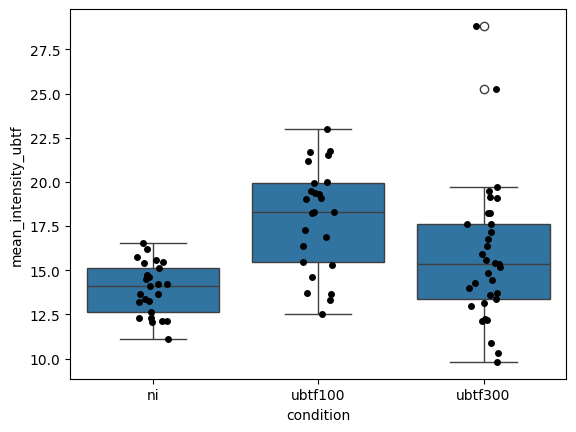

In [29]:
sns.boxplot(x=output_df.condition,y=output_df.mean_intensity_ubtf)
sns.stripplot(x=output_df.condition,y=output_df.mean_intensity_ubtf, color="black")